# Fuzzy Expert System (Mamdani) - HIGH-RECALL

Implements a **Mamdani** fuzzy inference system based on predictions from four base models:
- K-Nearest Neighbors
- Support Vector Machine
- Random Forest
- Multilayer Perceptron

> **System goal:** Maximise **Recall** for the Failure class while keeping the increase in false alarms at an acceptable level.

---
## 1. Library imports and model artifact loading


In [42]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    ConfusionMatrixDisplay, average_precision_score
)
import warnings
warnings.filterwarnings('ignore')

rf_art  = joblib.load('rf_artifacts.pkl')
svm_art = joblib.load('svm_artifacts.pkl')
knn_art = joblib.load('knn_artifacts.pkl')
mlp_art = joblib.load('mlp_artifacts.pkl')

p_rf  = rf_art['y_proba']
p_svm = svm_art['y_proba']
p_knn = knn_art['y_proba']
p_mlp = mlp_art['y_proba']
y_true = rf_art['y_test']

n = len(y_true)
print(f'Loaded predictions for {n} samples from the test set.')
print(f'RF ROC-AUC: {rf_art["roc_auc"]:.4f}')
print(f'SVM ROC-AUC: {svm_art["roc_auc"]:.4f}')
print(f'KNN ROC-AUC: {knn_art["roc_auc"]:.4f}')
print(f'MLP ROC-AUC: {mlp_art["roc_auc"]:.4f}')


Loaded predictions for 1500 samples from the test set.
RF ROC-AUC: 0.9614
SVM ROC-AUC: 0.9655
KNN ROC-AUC: 0.9534
MLP ROC-AUC: 0.9799


---
## 2. Mamdani fuzzy inference system design

### Input variables (universe: [0, 1])
Each input variable (`p_rf`, `p_svm`, `p_knn`, `p_mlp`) is described by three fuzzy sets:
- **LOW** - low failure probability
- **MEDIUM** - moderate failure probability
- **HIGH** - high failure probability

### Output variable (`failure_risk`, universe: [0, 1])
Five fuzzy sets: **VERY_LOW**, **LOW**, **MEDIUM**, **HIGH**, **VERY_HIGH**

In [43]:
u = np.linspace(0, 1, 101)

p_rf_var  = ctrl.Antecedent(u, 'p_rf')
p_svm_var = ctrl.Antecedent(u, 'p_svm')
p_knn_var = ctrl.Antecedent(u, 'p_knn')
p_mlp_var = ctrl.Antecedent(u, 'p_mlp')

risk_var = ctrl.Consequent(u, 'failure_risk', defuzzify_method='centroid')

# Input membership functions
for var in [p_rf_var, p_svm_var, p_knn_var, p_mlp_var]:
    var['LOW']    = fuzz.trapmf(u, [0.00, 0.00, 0.15, 0.30])
    var['MEDIUM'] = fuzz.trimf(u,  [0.20, 0.42, 0.65])
    var['HIGH']   = fuzz.trapmf(u, [0.45, 0.60, 1.00, 1.00])

# Output membership functions
risk_var['VERY_LOW']  = fuzz.trapmf(u, [0.00, 0.00, 0.08, 0.20])
risk_var['LOW']       = fuzz.trimf(u,  [0.08, 0.20, 0.38])
risk_var['MEDIUM']    = fuzz.trimf(u,  [0.30, 0.48, 0.62])
risk_var['HIGH']      = fuzz.trimf(u,  [0.50, 0.70, 0.88])
risk_var['VERY_HIGH'] = fuzz.trapmf(u, [0.68, 0.85, 1.00, 1.00])

print('Linguistic variables and membership functions defined.')


Linguistic variables and membership functions defined.


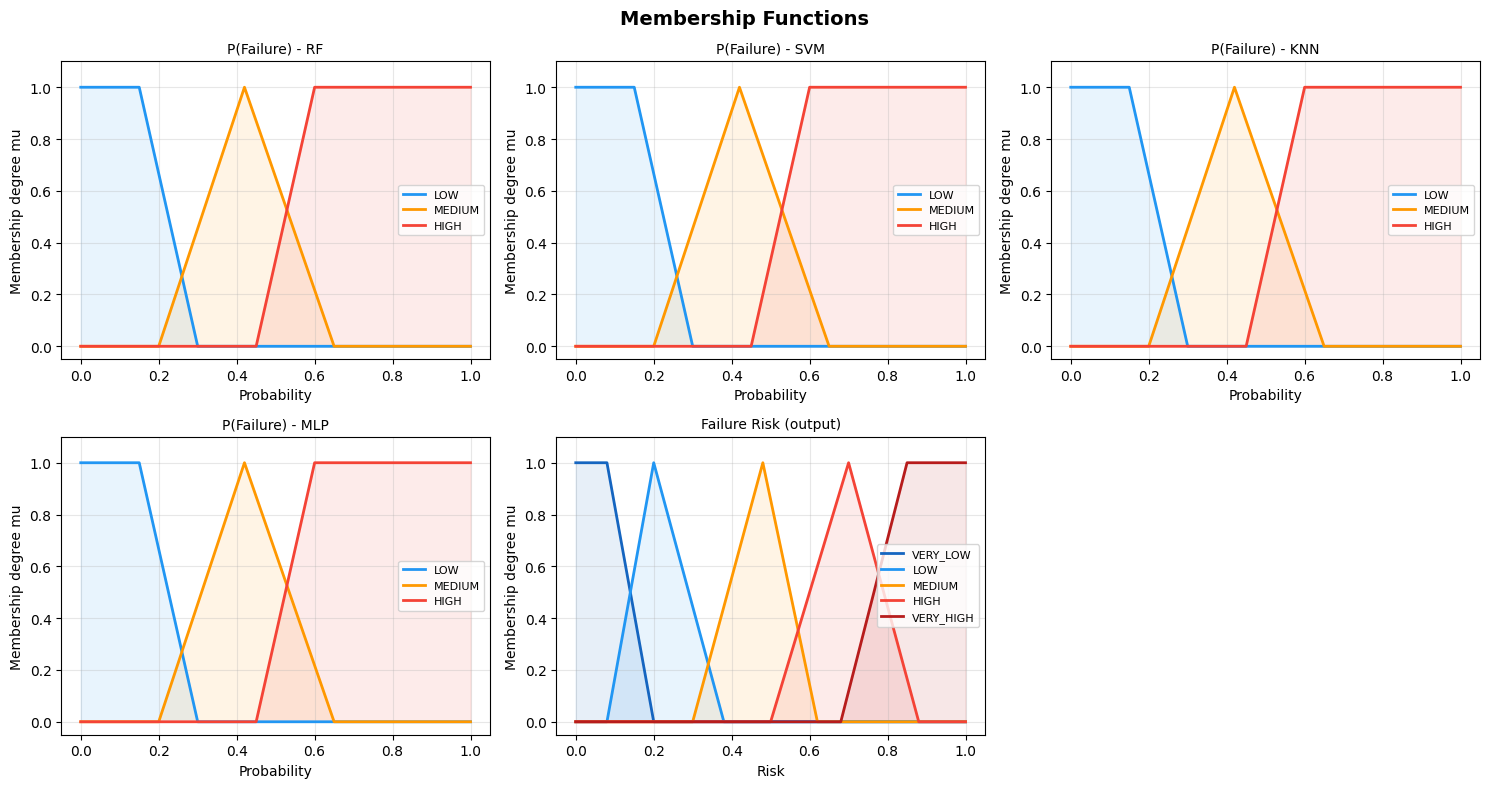

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Membership Functions', fontsize=14, fontweight='bold')

colors = {'LOW': '#2196F3', 'MEDIUM': '#FF9800', 'HIGH': '#F44336'}
out_colors = {'VERY_LOW': '#1565C0', 'LOW': '#2196F3', 'MEDIUM': '#FF9800',
              'HIGH': '#F44336', 'VERY_HIGH': '#B71C1C'}

input_vars = [
    (p_rf_var,  'P(Failure) - RF'),
    (p_svm_var, 'P(Failure) - SVM'),
    (p_knn_var, 'P(Failure) - KNN'),
    (p_mlp_var, 'P(Failure) - MLP'),
]

ax_flat = axes.flat
for (var, title), ax in zip(input_vars, ax_flat):
    for term, col in colors.items():
        ax.plot(u, var[term].mf, lw=2, label=term, color=col)
        ax.fill_between(u, var[term].mf, alpha=0.1, color=col)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Probability')
    ax.set_ylabel('Membership degree mu')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-0.05, 1.1)

flat_axes = axes.flatten()
ax_out = flat_axes[4]
for term, col in out_colors.items():
    ax_out.plot(u, risk_var[term].mf, lw=2, label=term, color=col)
    ax_out.fill_between(u, risk_var[term].mf, alpha=0.1, color=col)
ax_out.set_title('Failure Risk (output)', fontsize=10)
ax_out.set_xlabel('Risk')
ax_out.set_ylabel('Membership degree mu')
ax_out.legend(fontsize=8)
ax_out.grid(True, alpha=0.3)
ax_out.set_ylim(-0.05, 1.1)

flat_axes[5].axis('off')
plt.tight_layout()
plt.show()


---
## 3. Mamdani rule base

Rules are divided into three logical groups:

| Group | Description | Conclusion |
|-------|-------------|------------|
| **Consensus HIGH** | All / most models agree on high risk | VERY_HIGH / HIGH |
| **Consensus LOW** | All / most models indicate low risk | VERY_LOW / LOW |
| **Mixed** | Models disagree - ambiguous situation | MEDIUM |

In [45]:
rf  = p_rf_var
svm = p_svm_var
knn = p_knn_var
mlp = p_mlp_var
R   = risk_var

rules = [
    # Dominant rule: MLP HIGH => VERY_HIGH
    ctrl.Rule(mlp['HIGH'], R['VERY_HIGH'],
              label='R00_mlp_dominant'),

    # Full consensus HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['HIGH'] & mlp['HIGH'],
        R['VERY_HIGH'], label='R01_all_high'),

    # Three of four HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['HIGH'] & mlp['MEDIUM'],
        R['VERY_HIGH'], label='R02_3high_mlp_med'),
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & mlp['HIGH'] & knn['MEDIUM'],
        R['VERY_HIGH'], label='R03_3high_knn_med'),
    ctrl.Rule(
        rf['HIGH'] & knn['HIGH'] & mlp['HIGH'] & svm['MEDIUM'],
        R['VERY_HIGH'], label='R04_3high_svm_med'),
    ctrl.Rule(
        svm['HIGH'] & knn['HIGH'] & mlp['HIGH'] & rf['MEDIUM'],
        R['VERY_HIGH'], label='R05_3high_rf_med'),

    # Two HIGH + two MEDIUM
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R06_rf_svm_high'),
    ctrl.Rule(
        rf['HIGH'] & mlp['HIGH'] & svm['MEDIUM'] & knn['MEDIUM'],
        R['HIGH'], label='R07_rf_mlp_high'),
    ctrl.Rule(
        knn['HIGH'] & mlp['HIGH'] & rf['MEDIUM'] & svm['MEDIUM'],
        R['HIGH'], label='R08_knn_mlp_high'),
    ctrl.Rule(
        svm['HIGH'] & knn['HIGH'] & rf['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R09_svm_knn_high'),

    # One HIGH + rest MEDIUM => HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R10_only_rf_high'),
    ctrl.Rule(
        svm['HIGH'] & rf['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R11_only_svm_high'),
    ctrl.Rule(
        knn['HIGH'] & rf['MEDIUM'] & svm['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R12_only_knn_high'),
    ctrl.Rule(
        mlp['HIGH'] & rf['MEDIUM'] & svm['MEDIUM'] & knn['MEDIUM'],
        R['HIGH'], label='R13_only_mlp_high'),

    # Conflicts HIGH vs LOW => HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['LOW'],
        R['HIGH'], label='R14_rf_high_svm_low'),
    ctrl.Rule(
        knn['HIGH'] & mlp['LOW'],
        R['HIGH'], label='R15_knn_high_mlp_low'),
    ctrl.Rule(
        mlp['HIGH'] & rf['LOW'],
        R['HIGH'], label='R16_mlp_high_rf_low'),
    ctrl.Rule(
        svm['HIGH'] & knn['LOW'],
        R['HIGH'], label='R17_svm_high_knn_low'),

    # Two MEDIUM + two LOW => MEDIUM
    ctrl.Rule(
        rf['MEDIUM'] & svm['MEDIUM'] & knn['LOW'] & mlp['LOW'],
        R['MEDIUM'], label='R18b_rf_svm_med_low'),
    ctrl.Rule(
        knn['MEDIUM'] & mlp['MEDIUM'] & rf['LOW'] & svm['LOW'],
        R['MEDIUM'], label='R18c_knn_mlp_med_low'),

    # Full consensus MEDIUM
    ctrl.Rule(
        rf['MEDIUM'] & svm['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['MEDIUM'], label='R18_all_medium'),

    # Three HIGH + one LOW => HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['HIGH'] & mlp['LOW'],
        R['HIGH'], label='R19b_3high_1low'),

    # Two HIGH + two LOW: RF+MLP => HIGH, others => MEDIUM
    ctrl.Rule(
        rf['HIGH'] & mlp['HIGH'] & svm['LOW'] & knn['LOW'],
        R['HIGH'], label='R19c_rf_mlp_high_rest_low'),
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['LOW'] & mlp['LOW'],
        R['MEDIUM'], label='R19_rf_svm_high_knn_mlp_low'),
    ctrl.Rule(
        knn['HIGH'] & mlp['HIGH'] & rf['LOW'] & svm['LOW'],
        R['MEDIUM'], label='R20_knn_mlp_high_rf_svm_low'),

    # One HIGH + one MEDIUM (rest LOW) => MEDIUM
    ctrl.Rule(
        mlp['HIGH'] & rf['MEDIUM'] & svm['LOW'] & knn['LOW'],
        R['MEDIUM'], label='R20b_mlp_high_partial'),
    ctrl.Rule(
        rf['HIGH'] & mlp['MEDIUM'] & svm['LOW'] & knn['LOW'],
        R['MEDIUM'], label='R20c_rf_high_partial'),

    # Full consensus LOW
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & knn['LOW'] & mlp['LOW'],
        R['VERY_LOW'], label='R21_all_low'),

    # Three of four LOW
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & knn['LOW'] & mlp['MEDIUM'],
        R['LOW'], label='R22_3low_mlp_med'),
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & mlp['LOW'] & knn['MEDIUM'],
        R['LOW'], label='R23_3low_knn_med'),
    ctrl.Rule(
        rf['LOW'] & knn['LOW'] & mlp['LOW'] & svm['MEDIUM'],
        R['LOW'], label='R24_3low_svm_med'),
    ctrl.Rule(
        svm['LOW'] & knn['LOW'] & mlp['LOW'] & rf['MEDIUM'],
        R['LOW'], label='R25_3low_rf_med'),

    # Two LOW + two MEDIUM
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R26_rf_svm_low'),
    ctrl.Rule(
        knn['LOW'] & mlp['LOW'] & rf['MEDIUM'] & svm['MEDIUM'],
        R['LOW'], label='R27_knn_mlp_low'),

    # One LOW + rest MEDIUM
    ctrl.Rule(
        rf['LOW'] & svm['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R28_only_rf_low'),
    ctrl.Rule(
        svm['LOW'] & rf['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R29_only_svm_low'),
    ctrl.Rule(
        knn['LOW'] & rf['MEDIUM'] & svm['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R30_only_knn_low'),
    ctrl.Rule(
        mlp['LOW'] & rf['MEDIUM'] & svm['MEDIUM'] & knn['MEDIUM'],
        R['LOW'], label='R31_only_mlp_low'),
]

print(f'Rule base defined: {len(rules)} rules (HIGH-RECALL mode).')

Rule base defined: 38 rules (HIGH-RECALL mode).


---
## 4. Control system build and compilation

In [46]:
failure_ctrl = ctrl.ControlSystem(rules)
failure_sim  = ctrl.ControlSystemSimulation(failure_ctrl)

print(f'Number of rules: {len(rules)}')
print(f'Number of inputs: {len(list(failure_ctrl.antecedents))}')
print(f'Number of outputs: {len(list(failure_ctrl.consequents))}')
print(f'Defuzzification method: centroid')

Number of rules: 38
Number of inputs: 4
Number of outputs: 1
Defuzzification method: centroid
